# Notebook 28 — Calibrating depressing recurrence and testing spatial generalization

## Research question

Can an **additive, depressing recurrent synapse** with a conventional 1 ms absolute refractory period replace the sensory-dependent self-excitation of **ESCM 2.0 + fading**, while preserving or **improving** persistence, competition, and spatial generalization?

The approved model is a **benchmark, not a performance ceiling**. A candidate can be preferable even if its firing rates and currents differ from the reference, provided it produces meaningful transient representations, rapid competitive replacement, and reliable fading without excessive firing.

We explicitly distinguish **development** (isolated-neuron calibration and the original vertical/horizontal geometries) from **held-out validation** (the other three original geometries, three unseen shapes, asynchronous timing conditions, and timestep sensitivity). Parameters are selected **once** on development data, before held-out results are computed. There is no manual shape labeling inside either network.

We compare three implementations throughout: (1) approved ESCM 2.0 + fading, (2) additive excitation with sensory support, and (3) additive excitation + short-term depression (STD), **without support**. Camera, inhibition, membrane, and current dynamics are unchanged from Notebooks 25–27.

**Finite claim tested:** performance for the geometries, input sequences, parameter candidates, and timesteps explicitly enumerated here. Success on this finite battery does not establish general performance on real recordings.

## 1. Define the unchanged network and the development/validation stimuli

The network contains one current-based LIF neuron per pixel of a 9×9 lattice. Camera events target their corresponding neurons. Recurrent inhibition uses the same distance-dependent surround connectivity for **every** model; it is not configured for any particular shape:

\[
w^I_{ji}=0.1\exp\!\left(-\frac{d_{ij}^2}{2(2.5)^2}\right),\qquad 1.5<d_{ij}\leq5.5.
\]

The original five shapes are copied from Notebook 27. Vertical/horizontal are the **development** shapes. Diagonal/L-shaped/stepped, plus three predetermined unseen structures, are held out. Every old/new pair consists of two disjoint five-pixel patterns; the network receives only pixel events, never shape identities.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


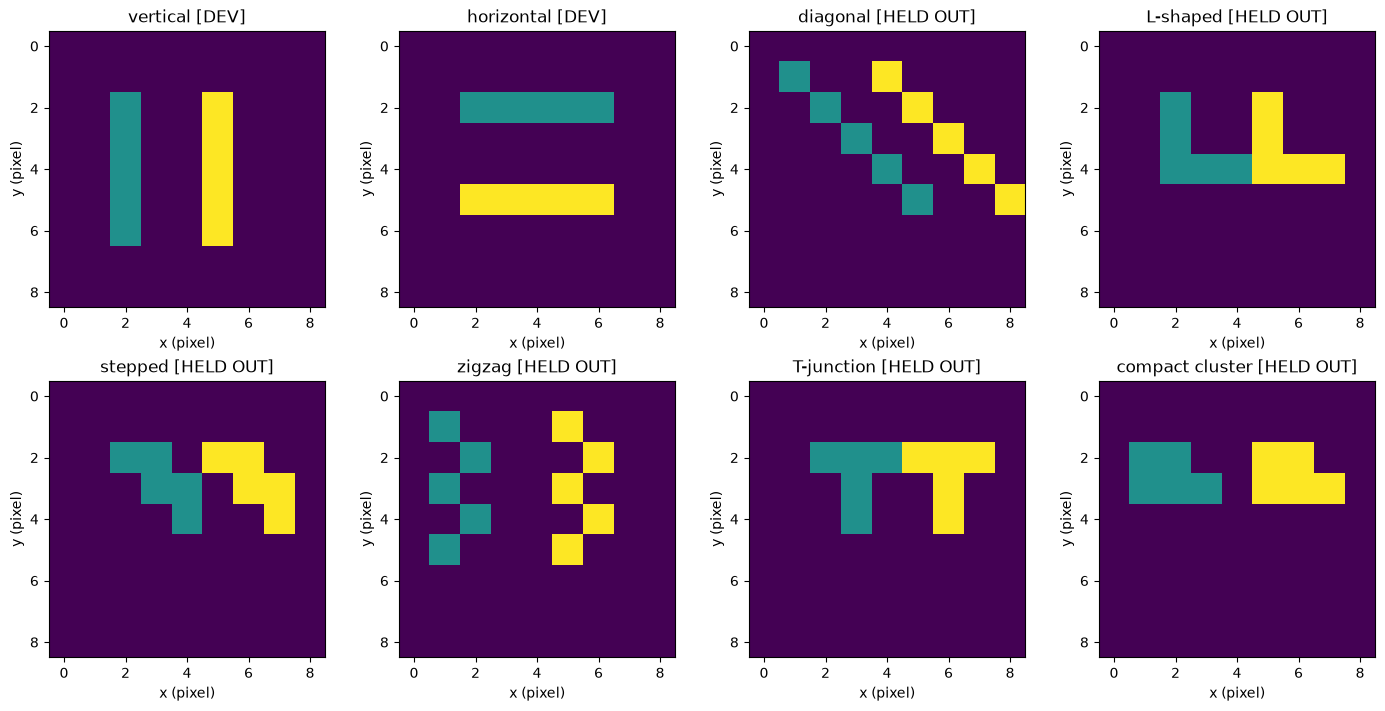

81 neurons, 3620 inhibitory synapses, 2 development and 6 held-out geometries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Many short simulations: avoid repeated C++ compilation.


width = height = 9
n = width * height
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
dt_ms = 0.05

def pixels(coords):
    return np.array([y * width + x for x, y in coords], dtype=int)

# Exact geometry definitions from Notebook 19 / 20.
shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x + 3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}

# Reused, homogeneous surround graph (same for both models and all input shapes).
distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1 * np.exp(-distance[post, pre]**2 / (2 * 2.5**2))
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())


# Three fixed, previously untested structures; excluded from parameter selection.
heldout_shapes = {
    "zigzag": (pixels([(1, 1), (2, 2), (1, 3), (2, 4), (1, 5)]),
               pixels([(5, 1), (6, 2), (5, 3), (6, 4), (5, 5)])),
    "T-junction": (pixels([(2, 2), (3, 2), (4, 2), (3, 3), (3, 4)]),
                   pixels([(5, 2), (6, 2), (7, 2), (6, 3), (6, 4)])),
    "compact cluster": (pixels([(1, 2), (2, 2), (1, 3), (2, 3), (3, 3)]),
                        pixels([(5, 2), (6, 2), (5, 3), (6, 3), (7, 3)])),
}
shapes.update(heldout_shapes)
development = ("vertical", "horizontal")
validation = ("diagonal", "L-shaped", "stepped", *heldout_shapes)
assert set(development).isdisjoint(validation)
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
for ax, (name, (old, new)) in zip(axes.flat, shapes.items()):
    grid = np.zeros(n, dtype=int)
    grid[old], grid[new] = 1, 2
    ax.imshow(grid.reshape(height, width), vmin=0, vmax=2,
              cmap="viridis", interpolation="nearest")
    ax.set(title=name + (" [DEV]" if name in development else " [HELD OUT]"),
           xlabel="x (pixel)", ylabel="y (pixel)",
           xticks=range(0, 9, 2), yticks=range(0, 9, 2))
for ax in list(axes.flat)[len(shapes):]:
    ax.axis("off")
plt.show()
print(f"{n} neurons, {len(pre)} inhibitory synapses, "
      f"{len(development)} development and {len(validation)} held-out geometries")

## 2. Implement the three neuronal/synaptic models

All variants obey the same membrane/current equations:

\[
\tau_m\dot v=-v+I_{\rm ext}+I_{\rm exc}-I_{\rm inh},\quad
\tau_\alpha\dot I_\alpha=-I_\alpha,
\]

with \(\tau_m=10\) ms, \(\tau_{\rm ext}=3\) ms, \(\tau_{\rm exc}=5\) ms, \(\tau_{\rm inh}=12\) ms, threshold 1, reset 0, and an external camera increment of 22. The **reference** overwrites recurrence as \(I_{\rm exc}\leftarrow8s\), with \(\tau_s=120\) ms and camera-triggered \(s\leftarrow1\). The additive control instead uses \(I_{\rm exc}\leftarrow I_{\rm exc}+3s\). Their reference/refractory conditions are 0 and 1 ms, respectively.

**STD** has no \(s\). Its recurrent synapse stores the available-resource fraction \(x\), initialized to 1 and recovering toward 1 between presynaptic spikes:

\[
\tau_{\rm rec}\dot x=1-x,\qquad
I_{\rm exc}\leftarrow I_{\rm exc}+J_0x,\qquad x\leftarrow(1-U)x.
\]

The two event-triggered assignments are on the same self-synapse; the current uses the **pre-depletion** resource. The refractory period blocks spikes, **not current decay**. The implementation follows the Brian2 conventions of Notebook 27 directly; every simulation begins from a fresh network and has the same input timestamps.

In [2]:
def simulate(schedule, *, mode, weight, refractory_ms, U=0.1, tau_rec_ms=120.,
             duration_ms=260., n_neurons=n, trace_ids=None, dt=dt_ms):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    event_ids, event_times = [], []
    for ids, pulses, stagger_ms in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(ids):
                event_ids.append(int(pixel))
                event_times.append(float(pulse) + j * stagger_ms)
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n_neurons, np.asarray(event_ids, dtype=int)[order],
        np.asarray(event_times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      tau_support=120*b2.ms, v_threshold=1., camera_gain=22.)
    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode != "std":
        equations += "dsupport/dt = -support/tau_support : 1\n"
    neurons = b2.NeuronGroup(
        n_neurons, equations, threshold="v > v_threshold", reset="v = 0",
        refractory=refractory_ms*b2.ms if refractory_ms else False,
        method="exact", namespace=parameters)

    camera_update = "Iext_post += camera_gain"
    if mode != "std":
        camera_update += "; support_post = 1"
    feed = b2.Synapses(camera, neurons, on_pre=camera_update, namespace=parameters)
    feed.connect(j="i")

    if mode == "std":
        recurrence = b2.Synapses(
            neurons, neurons,
            "dx/dt = (1-x)/tau_recovery : 1 (event-driven)",
            on_pre="Iexc_post += std_increment*x; x = x*(1-std_utilization)",
            namespace={"std_increment": float(weight),
                       "std_utilization": float(U),
                       "tau_recovery": float(tau_rec_ms)*b2.ms})
    elif mode == "refresh":
        recurrence = b2.Synapses(
            neurons, neurons, on_pre="Iexc_post = recurrence_gain*support_post",
            namespace={"recurrence_gain": float(weight)})
    elif mode == "additive":
        recurrence = b2.Synapses(
            neurons, neurons, on_pre="Iexc_post += recurrence_gain*support_post",
            namespace={"recurrence_gain": float(weight)})
    else:
        raise ValueError(mode)
    recurrence.connect(i=np.arange(n_neurons), j=np.arange(n_neurons))
    if mode == "std":
        recurrence.x = 1.

    spikes = b2.SpikeMonitor(neurons)
    objects = [camera, neurons, feed, recurrence, spikes]
    if n_neurons == n:
        inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        inhibition.connect(i=pre, j=post)
        inhibition.w = base_inhibition
        objects.append(inhibition)
    if trace_ids is not None:
        variables = ["v", "Iext", "Iexc", "Iinh"]
        if mode != "std":
            variables.append("support")
        state = b2.StateMonitor(neurons, variables, record=trace_ids)
        objects.append(state)
        if mode == "std":
            resource = b2.StateMonitor(recurrence, "x", record=trace_ids)
            objects.append(resource)

    b2.Network(*objects).run(duration_ms*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms),
              "i": np.asarray(spikes.i, dtype=int)}
    if trace_ids is not None:
        result["time"] = np.asarray(state.t/b2.ms)
        for var in variables:
            result[var] = np.asarray(getattr(state, var))
        if mode == "std":
            result["x"] = np.asarray(resource.x)
    return result

reference = dict(mode="refresh", weight=8., refractory_ms=0.)
additive = dict(mode="additive", weight=3., refractory_ms=1.)
old_pulses = (2., 4., 6.)
windows = ((32., 42.), (42., 52.))

def pulse_schedule(old, new, second_start=20., row_delay=0.):
    return ((old, old_pulses, row_delay),
            (new, (second_start, second_start+2., second_start+4.), row_delay))

## 3. Derive STD's operating point before selecting candidates

A fixed recurrent spike interval \(T\) permits an **exact** expression for the resource available immediately before each spike. Let \(a=e^{-T/\tau_{\rm rec}}\). From the event-driven dynamics,

\[
x_{k+1}^{-}=1-\left[1-(1-U)x_k^{-}\right]a,
\qquad
\boxed{x_*^- = \frac{1-a}{1-(1-U)a}}.
\]

At this fixed-interval operating point, the recurrent impulse is \(J_0x_*^-\). Since the excitatory current decays exponentially between spikes, its **time-averaged** value is exactly

\[
\boxed{\langle I_{\rm exc}\rangle=J_0x_*^-\frac{\tau_{\rm exc}}{T}}.
\]

Consequently, for a target mean excitation \(\overline I_{\rm target}\),

\[
\boxed{J_0=\overline I_{\rm target}\frac{T}{\tau_{\rm exc}x_*^-}}.
\]

These identities are **conditional on regular firing** and do not imply that the nonlinear recurrent network will fire at that interval. We use them to propose candidate weights, then measure the actual firing, currents and fading in Brian2. The reference's mean excitation is measured in a post-camera, pre-competition period from its isolated neuron rather than imposing an arbitrary target.

In [3]:
solo_schedule = [(np.array([0], dtype=int), old_pulses, 0.)]
solo_ref_trace = simulate(solo_schedule, **reference, n_neurons=1,
                          duration_ms=260., trace_ids=[0])
solo_add_trace = simulate(solo_schedule, **additive, n_neurons=1,
                          duration_ms=260., trace_ids=[0])

# Compare currents when camera drive is mostly gone but the reference still fires.
target_interval = (12., 22.)
period = (solo_ref_trace["time"] >= target_interval[0]) & (solo_ref_trace["time"] < target_interval[1])
target_exc = float(solo_ref_trace["Iexc"][0, period].mean())
assert target_exc > 0

# Two plausible interspike intervals for the 1 ms refractory candidate.
# Nominal frequency is an input to the analytical proposal, not an observed result.
resource_rows = []
for utilization in (0.025, 0.05, 0.10, 0.15):
    for recovery_ms in (80., 160.):
        for interval_ms in (1.5, 2.5):
            a = np.exp(-interval_ms/recovery_ms)
            x_star = (1-a)/(1-(1-utilization)*a)
            J_match = target_exc*interval_ms/(5.*x_star)
            resource_rows.append((utilization, recovery_ms, interval_ms, x_star, J_match))
analytical = pd.DataFrame(resource_rows,
                          columns=["U", "tau_rec_ms", "T_ms", "x_pre_star", "J_match"])
print(f"Reference mean recurrent excitation, {target_interval[0]:g}–{target_interval[1]:g} ms: "
      f"{target_exc:.3f} model units")
display(analytical.round(3))

# Sanity check against the discrete resource recursion; independent of Brian2.
for row in analytical.itertuples(index=False):
    x = 1.
    for _ in range(20000):
        x = 1-(1-(1-row.U)*x)*np.exp(-row.T_ms/row.tau_rec_ms)
    assert abs(x-row.x_pre_star) < 1e-10
print("PASS: analytical steady-state resources agree with direct event recursion.")

Reference mean recurrent excitation, 12–22 ms: 6.468 model units


,U,tau_rec_ms,T_ms,x_pre_star,J_match
0,0.025,80.0,1.5,0.431,4.503
1,0.025,80.0,2.5,0.559,5.781
2,0.025,160.0,1.5,0.274,7.091
3,0.025,160.0,2.5,0.386,8.368
4,0.050,80.0,1.5,0.275,7.066
5,0.050,80.0,2.5,0.388,8.328
6,0.050,160.0,1.5,0.159,12.241
7,0.050,160.0,2.5,0.240,13.502
8,0.100,80.0,1.5,0.159,12.192
9,0.100,80.0,2.5,0.241,13.422


PASS: analytical steady-state resources agree with direct event recursion.


## 4. Isolated-neuron calibration: avoid weak and runaway synapses

The analytical \(J_{\rm match}\) is only a starting point. For each combination of resource utilization and recovery time, test two nearby strengths (0.8× and 1.6× the derived increment). Include the previously tested \((J_0,U,\tau_{\rm rec})=(8,0.05,120\,\mathrm{ms})\) as an anchor. **No sensory support exists** in these runs.

The target is **temporary**, not indefinitely self-sustained firing. We measure the last spike after camera input, spikes during the 200–260 ms silent tail, refractory violations, and average excitation in 12–22 ms. This stage removes clearly unhelpful candidates and keeps a diverse shortlist; it does **not** optimize the five-geometry replacement score.

Candidates with inadequate persistence are ranked behind those that remain active beyond the development replacement window. Firing beyond 200 ms is explicitly penalized. The reference last-spike time is a soft comparison rather than an equality constraint, so a good candidate can outperform the reference.

In [4]:
def solo_metrics(run):
    t = run["t"]
    intervals = np.diff(t)
    return dict(last_spike_ms=float(t[-1]) if len(t) else 0.,
                post_input_spikes=int(np.sum(t >= 10.)),
                tail_spikes=int(np.sum((t >= 200.) & (t < 260.))),
                minimum_isi_ms=float(intervals.min()) if len(intervals) else np.nan)

# Candidate set from the exact operating-point formula, plus an observed anchor.
parameter_sets = {(8., 0.05, 120.)}
for row in analytical.itertuples(index=False):
    for factor in (0.8, 1.6):
        J0 = round(float(np.clip(factor*row.J_match, 1.5, 15.)), 3)
        parameter_sets.add((J0, row.U, row.tau_rec_ms))

single_rows = []
for J0, utilization, recovery_ms in tqdm(sorted(parameter_sets), desc="STD isolated-neuron calibration"):
    cfg = dict(mode="std", weight=J0, refractory_ms=1.,
               U=utilization, tau_rec_ms=recovery_ms)
    # State trace is inexpensive for one neuron and enables current diagnostics.
    run = simulate(solo_schedule, **cfg, n_neurons=1,
                   duration_ms=260., trace_ids=[0])
    t = run["time"]
    during = (t >= target_interval[0]) & (t < target_interval[1])
    metrics = solo_metrics(run)
    single_rows.append(dict(J0=J0, U=utilization, tau_rec_ms=recovery_ms,
                            early_mean_exc=float(run["Iexc"][0, during].mean()),
                            **metrics))
calibration = pd.DataFrame(single_rows)
calibration["relative_exc_error"] = abs(calibration.early_mean_exc-target_exc)/target_exc
calibration["can_compete"] = calibration.last_spike_ms >= 53.
calibration["eventual_fading"] = calibration.tail_spikes == 0
# The goal is not to match last-spike timing exactly; it is to preserve useful
# activity, remain bounded, and avoid excessively high recurrent drive.
calibration["solo_score"] = (
    2.0 * (~calibration.can_compete).astype(int)
    + 5.0 * (~calibration.eventual_fading).astype(int)
    + calibration.relative_exc_error.clip(upper=5)
    + abs(calibration.last_spike_ms-90.)/150.
)
calibration = calibration.sort_values("solo_score").reset_index(drop=True)
display(calibration.head(20).round(3))

# Compare against the approved model without imposing exact equality.
print("ESCM 2.0 isolated neuron:", solo_metrics(solo_ref_trace))
print("Additive + support control:", solo_metrics(solo_add_trace))

# Take candidates that satisfy both scientifically important controls first;
# fall back to the best-ranked candidates if none satisfy them.
viable = calibration.query("can_compete and eventual_fading")
shortlist = (viable if len(viable) else calibration).head(10).copy()
print(f"{len(viable)} viable isolated-neuron candidates; {len(shortlist)} shortlisted")
display(shortlist[["J0", "U", "tau_rec_ms", "last_spike_ms", "early_mean_exc", "tail_spikes"]])

STD isolated-neuron calibration:   4%|▍         | 1/24 [00:01<00:23,  1.04s/it]WARNING    't' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value array([0.0000e+00, 5.0000e-02, 1.0000e-01, ..., 2.5985e+02, 2.5990e+02,
       2.5995e+02], shape=(5200,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
STD isolated-neuron calibration: 100%|██████████| 24/24 [00:09<00:00,  2.56it/s]


,J0,U,tau_rec_ms,early_mean_exc,last_spike_ms,post_input_spikes,tail_spikes,minimum_isi_ms,relative_exc_error,can_compete,eventual_fading,solo_score
0,3.603,0.025,80.0,13.462,69.35,43,0,1.0,1.081,True,True,1.219
1,5.653,0.050,80.0,16.839,64.35,38,0,1.0,1.604,True,True,1.775
2,9.754,0.100,80.0,18.997,56.15,30,0,1.0,1.937,True,True,2.163
3,5.672,0.025,160.0,20.977,95.60,67,0,1.0,2.243,True,True,2.281
4,8.000,0.050,120.0,23.499,70.00,47,0,1.0,2.633,True,True,2.766
5,6.694,0.025,160.0,24.757,114.10,84,0,1.0,2.828,True,True,2.988
6,9.793,0.050,160.0,28.557,74.45,51,0,1.0,3.415,True,True,3.519
7,10.802,0.050,160.0,31.499,88.60,58,0,1.0,3.870,True,True,3.879
8,15.000,0.150,160.0,18.538,33.60,19,0,1.0,1.866,False,True,4.242
9,15.000,0.100,160.0,27.910,50.65,31,0,1.0,3.315,False,True,5.577


ESCM 2.0 isolated neuron: {'last_spike_ms': 89.2, 'post_input_spikes': 34, 'tail_spikes': 0, 'minimum_isi_ms': 0.2499999999999991}
Additive + support control: {'last_spike_ms': 85.7, 'post_input_spikes': 64, 'tail_spikes': 0, 'minimum_isi_ms': 0.9999999999999929}
8 viable isolated-neuron candidates; 8 shortlisted


,J0,U,tau_rec_ms,last_spike_ms,early_mean_exc,tail_spikes
0,3.603,0.025,80.0,69.35,13.462407,0
1,5.653,0.050,80.0,64.35,16.839345,0
2,9.754,0.100,80.0,56.15,18.997055,0
3,5.672,0.025,160.0,95.60,20.977498,0
4,8.000,0.050,120.0,70.00,23.498836,0
5,6.694,0.025,160.0,114.10,24.757294,0
6,9.793,0.050,160.0,74.45,28.557153,0
7,10.802,0.050,160.0,88.60,31.499476,0


## 5. Calibrate spatial replacement on **two development geometries only**

Reproduce Notebook 27's strict competition test. The old shape receives camera pulses at 2, 4 and 6 ms. The new shape receives pulses at 20, 22 and 24 ms. Every setting is tested independently with **old-only**, **new-only**, and **combined** input. All five pixels in each isolated control must fire at least twice in **both** [32,42) and [42,52) ms windows. Otherwise, a disappearing old shape is *not* counted as inhibition-driven replacement.

A strict replacement requires: all five old pixels silent in both windows; all five new pixels firing in both; and no off-target spikes. This is identical to Notebook 27's strict scoring. We additionally record how many pixels meet each condition and **latency from the final new-camera pulse** to the last obsolete spike. Latency is only meaningful when all old pixels are silent during the late evaluation window and the old-only control establishes persistence.

Parameter selection uses only **vertical and horizontal**. Ranking rewards strict successes first, then eligibility, new-pixel recruitment and obsolete-pixel suppression. Held-out shapes and timing results are not consulted.

In [5]:
def pixel_counts(run, ids, start, stop):
    mask = (run["t"] >= start) & (run["t"] < stop)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate_one(geometry, setting, *, second_start=20., row_delay=0.):
    old, new = shapes[geometry]
    old_input, new_input = pulse_schedule(old, new, second_start, row_delay)
    # Evaluate at a fixed delay from the most recent new-camera event.
    evaluation_windows = ((second_start + 12., second_start + 22.),
                          (second_start + 22., second_start + 32.))
    end_ms = max(80., second_start+44.)
    old_only = simulate([old_input], **setting, duration_ms=end_ms)
    new_only = simulate([new_input], **setting, duration_ms=end_ms)
    both = simulate([old_input, new_input], **setting, duration_ms=end_ms)
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])

    def per_window(run, ids):
        return np.array([pixel_counts(run, ids, a, b) for a, b in evaluation_windows])

    old_ctrl = (per_window(old_only, old) >= 2).all(axis=0)
    new_ctrl = (per_window(new_only, new) >= 2).all(axis=0)
    old_quiet = (per_window(both, old) == 0).all(axis=0)
    new_active = (per_window(both, new) >= 2).all(axis=0)
    off_target = (per_window(both, outside) > 0).any(axis=0)
    eligible = bool(old_ctrl.all() and new_ctrl.all())
    success = bool(eligible and old_quiet.all() and new_active.all() and not off_target.any())
    last_old = both["t"][np.isin(both["i"], old)]
    last_old_after_new = last_old[last_old >= second_start]
    # A useful latency must correspond to actual suppression, not later fading.
    latency = (float(last_old_after_new[-1] - (second_start+4.+4*row_delay))
               if eligible and old_quiet.all() and len(last_old_after_new) else np.nan)
    return dict(geometry=geometry, eligible=eligible, success=success,
                old_control=int(old_ctrl.sum()), new_control=int(new_ctrl.sum()),
                old_silent=int(old_quiet.sum()), new_persistent=int(new_active.sum()),
                off_target=int(off_target.sum()), suppression_latency_ms=latency)

def geometry_table(setting, names):
    return pd.DataFrame([evaluate_one(name, setting) for name in names])

reference_development = geometry_table(reference, development)
control_development = geometry_table(additive, development)
assert reference_development.success.all(), "Reference reproduction failed; inspect before selecting STD"

calibration_rows = []
for row in tqdm(shortlist.itertuples(index=False), total=len(shortlist),
                desc="STD development-geometry comparison"):
    cfg = dict(mode="std", weight=float(row.J0), refractory_ms=1.,
               U=float(row.U), tau_rec_ms=float(row.tau_rec_ms))
    results = geometry_table(cfg, development)
    calibration_rows.append(dict(J0=row.J0, U=row.U, tau_rec_ms=row.tau_rec_ms,
                                 successes=int(results.success.sum()),
                                 eligible=int(results.eligible.sum()),
                                 old_silent=int(results.old_silent.sum()),
                                 new_persistent=int(results.new_persistent.sum()),
                                 off_target=int(results.off_target.sum()),
                                 solo_score=row.solo_score,
                                 last_spike_ms=row.last_spike_ms))
trained = pd.DataFrame(calibration_rows).sort_values(
    ["successes", "eligible", "new_persistent", "old_silent", "off_target", "solo_score"],
    ascending=[False, False, False, False, True, True]
).reset_index(drop=True)
display(trained)

winner = trained.iloc[0]
selected_std = dict(mode="std", weight=float(winner.J0), refractory_ms=1.,
                    U=float(winner.U), tau_rec_ms=float(winner.tau_rec_ms))
print("LOCKED STD candidate:", selected_std)
print("Development benchmark: reference", int(reference_development.success.sum()),
      "/2; STD", int(winner.successes), "/2")

STD development-geometry comparison: 100%|██████████| 8/8 [00:08<00:00,  1.12s/it]


,J0,U,tau_rec_ms,successes,eligible,old_silent,new_persistent,off_target,solo_score,last_spike_ms
0,3.603,0.025,80.0,0,2,0,10,0,1.219076,69.35
1,5.672,0.025,160.0,0,2,0,10,0,2.280643,95.60
2,8.000,0.050,120.0,0,2,0,10,0,2.766465,70.00
3,6.694,0.025,160.0,0,2,0,10,0,2.988367,114.10
4,9.793,0.050,160.0,0,2,0,10,0,3.518860,74.45
5,10.802,0.050,160.0,0,2,0,10,0,3.879436,88.60
6,9.754,0.100,80.0,0,0,6,10,0,2.162782,56.15
7,5.653,0.050,80.0,0,0,0,10,0,1.774514,64.35


LOCKED STD candidate: {'mode': 'std', 'weight': 3.603, 'refractory_ms': 1.0, 'U': 0.025, 'tau_rec_ms': 80.0}
Development benchmark: reference 2 /2; STD 0 /2


## 6. Lock parameters and evaluate **unseen spatial geometries**

The STD parameter set printed above is now **fixed**. Run it alongside the approved ESCM 2.0 and additive-with-support control on the complete eight-geometry battery. Only the first two shapes were used during parameter selection. The remaining six are **held out**, including the three original hard cases and three additional structures with different local neighbor arrangements.

For each shape, display isolated-control eligibility, silent obsolete pixels, persistent new pixels, off-target activity, binary strict success, and suppression latency. A model can outperform the reference in **held-out** replacement without matching its internal current amplitudes.

Locked-parameter spatial validation: 100%|██████████| 3/3 [00:12<00:00,  4.26s/it]


,model,geometry,split,eligible,success,old_control,new_control,old_silent,new_persistent,off_target,suppression_latency_ms
0,ESCM 2.0 + fading,vertical,development,True,True,5,5,5,5,0,-1.20
1,ESCM 2.0 + fading,horizontal,development,True,True,5,5,5,5,0,-1.20
2,ESCM 2.0 + fading,diagonal,held out,True,False,5,5,4,5,0,NaN
3,ESCM 2.0 + fading,L-shaped,held out,True,False,5,5,5,4,0,0.55
4,ESCM 2.0 + fading,stepped,held out,True,True,5,5,5,5,0,1.40
5,ESCM 2.0 + fading,zigzag,held out,True,True,5,5,5,5,0,0.65
6,ESCM 2.0 + fading,T-junction,held out,False,False,4,4,5,4,0,NaN
7,ESCM 2.0 + fading,compact cluster,held out,True,False,5,5,3,5,0,NaN
8,Additive + support,vertical,development,True,False,5,5,0,5,0,NaN
9,Additive + support,horizontal,development,True,False,5,5,0,5,0,NaN


,model,split,tested,eligible,strict_success,mean_old_silent,mean_new_active,total_off_target
0,ESCM 2.0 + fading,development,2,2,2,5.00,5.00,0
1,ESCM 2.0 + fading,held out,6,5,2,4.50,4.67,0
2,Additive + support,development,2,2,0,0.00,5.00,0
3,Additive + support,held out,6,6,0,0.00,5.00,0
4,STD (locked),development,2,2,0,0.00,5.00,0
5,STD (locked),held out,6,3,0,0.33,5.00,0


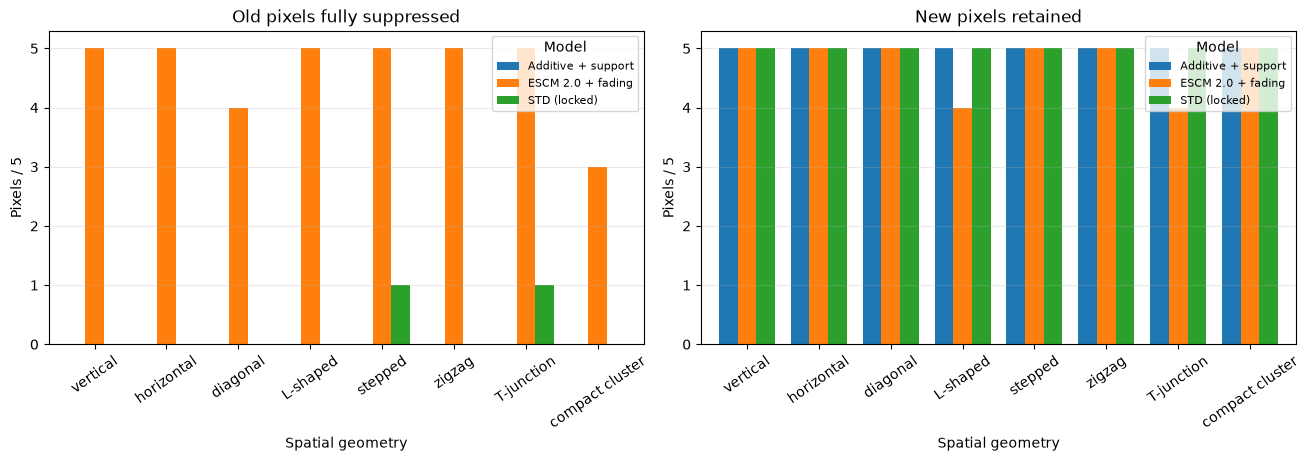

In [6]:
settings = {"ESCM 2.0 + fading": reference,
            "Additive + support": additive,
            "STD (locked)": selected_std}
records = []
for name, cfg in tqdm(settings.items(), desc="Locked-parameter spatial validation"):
    table = geometry_table(cfg, (*development, *validation))
    table.insert(0, "model", name)
    table.insert(2, "split", np.where(table.geometry.isin(development),
                                     "development", "held out"))
    records.append(table)
spatial = pd.concat(records, ignore_index=True)
display(spatial)
summary = spatial.groupby(["model", "split"], sort=False).agg(
    tested=("geometry", "size"), eligible=("eligible", "sum"),
    strict_success=("success", "sum"),
    mean_old_silent=("old_silent", "mean"),
    mean_new_active=("new_persistent", "mean"),
    total_off_target=("off_target", "sum")
).reset_index()
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, variable, title in zip(axes,
                               ("old_silent", "new_persistent"),
                               ("Old pixels fully suppressed", "New pixels retained")):
    values = spatial.pivot(index="geometry", columns="model", values=variable)
    values.loc[list((*development, *validation))].plot.bar(ax=ax, width=0.78)
    ax.set(title=title, ylabel="Pixels / 5", xlabel="Spatial geometry", ylim=(0, 5.3))
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Model", fontsize=8)
    ax.grid(axis="y", alpha=0.25)
plt.show()

## 7. Temporal generalization — independent of calibration

An event-camera representation must handle asynchronous event arrival. Holding the selected parameters fixed, test the 16 timing conditions from the earlier spatial validation approach: new edge onset at 16, 20, 28, or 40 ms, combined with 0, 0.25, 0.5, or 1 ms per-pixel staggering. The evaluation windows move with the new edge, so they always sample the same time after its onset.

**Important:** these timing challenges use the development vertical geometry but novel timings; they test temporal robustness, not held-out spatial shape generalization. A late-onset test can become **ineligible** if the old control naturally fades before the competition window. Report ineligibility separately rather than treating it as replacement failure or success.

Asynchronous timing validation: 100%|██████████| 3/3 [00:29<00:00,  9.67s/it]


,eligible,successes,old_silent_mean,new_active_mean
model,,,,
Additive + support,12,0,0.6250,5.0
ESCM 2.0 + fading,15,15,5.0000,5.0
STD (locked),5,0,1.8125,5.0


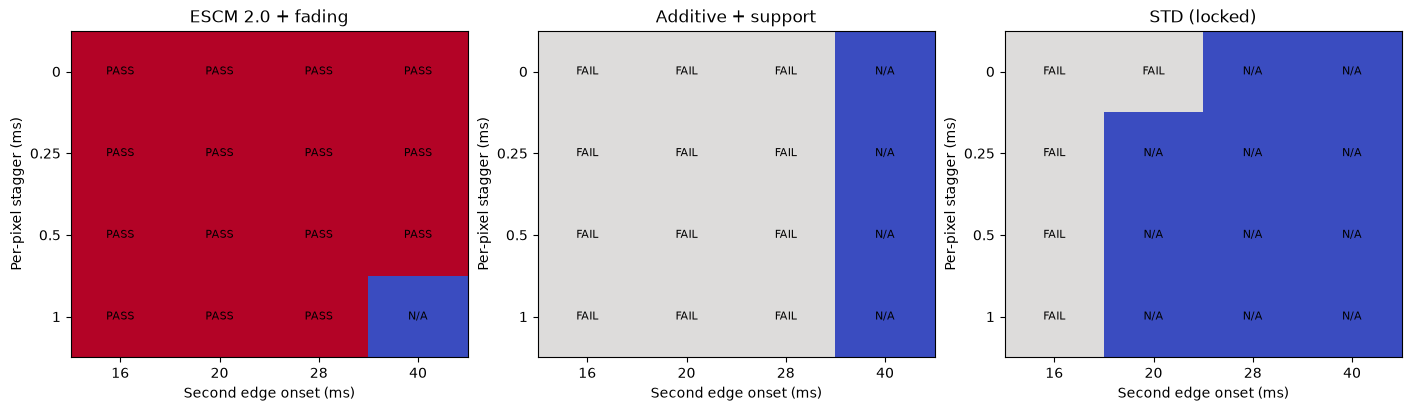

N/A means isolated controls were not eligible; it is not a success.


In [7]:
timing_records = []
for name, cfg in tqdm(settings.items(), desc="Asynchronous timing validation"):
    for onset in (16., 20., 28., 40.):
        for stagger in (0., 0.25, 0.5, 1.):
            result = evaluate_one("vertical", cfg, second_start=onset, row_delay=stagger)
            timing_records.append(dict(model=name, onset_ms=onset,
                                       stagger_ms=stagger, **result))
timing = pd.DataFrame(timing_records)
display(timing.groupby("model").agg(eligible=("eligible", "sum"),
                                   successes=("success", "sum"),
                                   old_silent_mean=("old_silent", "mean"),
                                   new_active_mean=("new_persistent", "mean")))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (name, frame) in zip(axes, timing.groupby("model", sort=False)):
    success_map = frame.pivot(index="stagger_ms", columns="onset_ms", values="success")
    eligibility_map = frame.pivot(index="stagger_ms", columns="onset_ms", values="eligible")
    state = np.where(~eligibility_map.to_numpy(), -1, success_map.to_numpy().astype(int))
    ax.imshow(state, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest", aspect="auto")
    ax.set(title=name, xlabel="Second edge onset (ms)",
           ylabel="Per-pixel stagger (ms)",
           xticks=range(4), xticklabels=[16,20,28,40],
           yticks=range(4), yticklabels=[0,0.25,0.5,1])
    for i in range(4):
        for j in range(4):
            ax.text(j, i, {1:"PASS", 0:"FAIL", -1:"N/A"}[state[i,j]],
                    ha="center", va="center", fontsize=8, color="black")
plt.show()
print("N/A means isolated controls were not eligible; it is not a success.")

## 8. Numerical robustness and mechanistic current traces

Without retuning, repeat the held-out geometries at \(\Delta t\in\{0.1,0.05,0.025\}\) ms. This tests whether classification depends on integration resolution. Reproduce each candidate at the same step; the analytical parameter proposal does **not** change when the timestep changes.

Finally, plot the time courses in the development vertical-edge replacement, comparing old/new excitation, inhibition, net drive, and STD resources. Read these plots alongside the results: a large excitatory current alone cannot prove the mechanism of failed competition without accounting for inhibition and spike timing.

Timestep robustness: 100%|██████████| 3/3 [00:38<00:00, 12.78s/it]


,model,dt_ms,eligible,strict_success
0,Additive + support,0.025,6,0
1,Additive + support,0.050,6,0
2,Additive + support,0.100,6,0
3,ESCM 2.0 + fading,0.025,5,2
4,ESCM 2.0 + fading,0.050,5,2
5,ESCM 2.0 + fading,0.100,5,2
6,STD (locked),0.025,3,0
7,STD (locked),0.050,3,0
8,STD (locked),0.100,3,0


Current-balance traces: 100%|██████████| 3/3 [00:00<00:00,  3.52it/s]


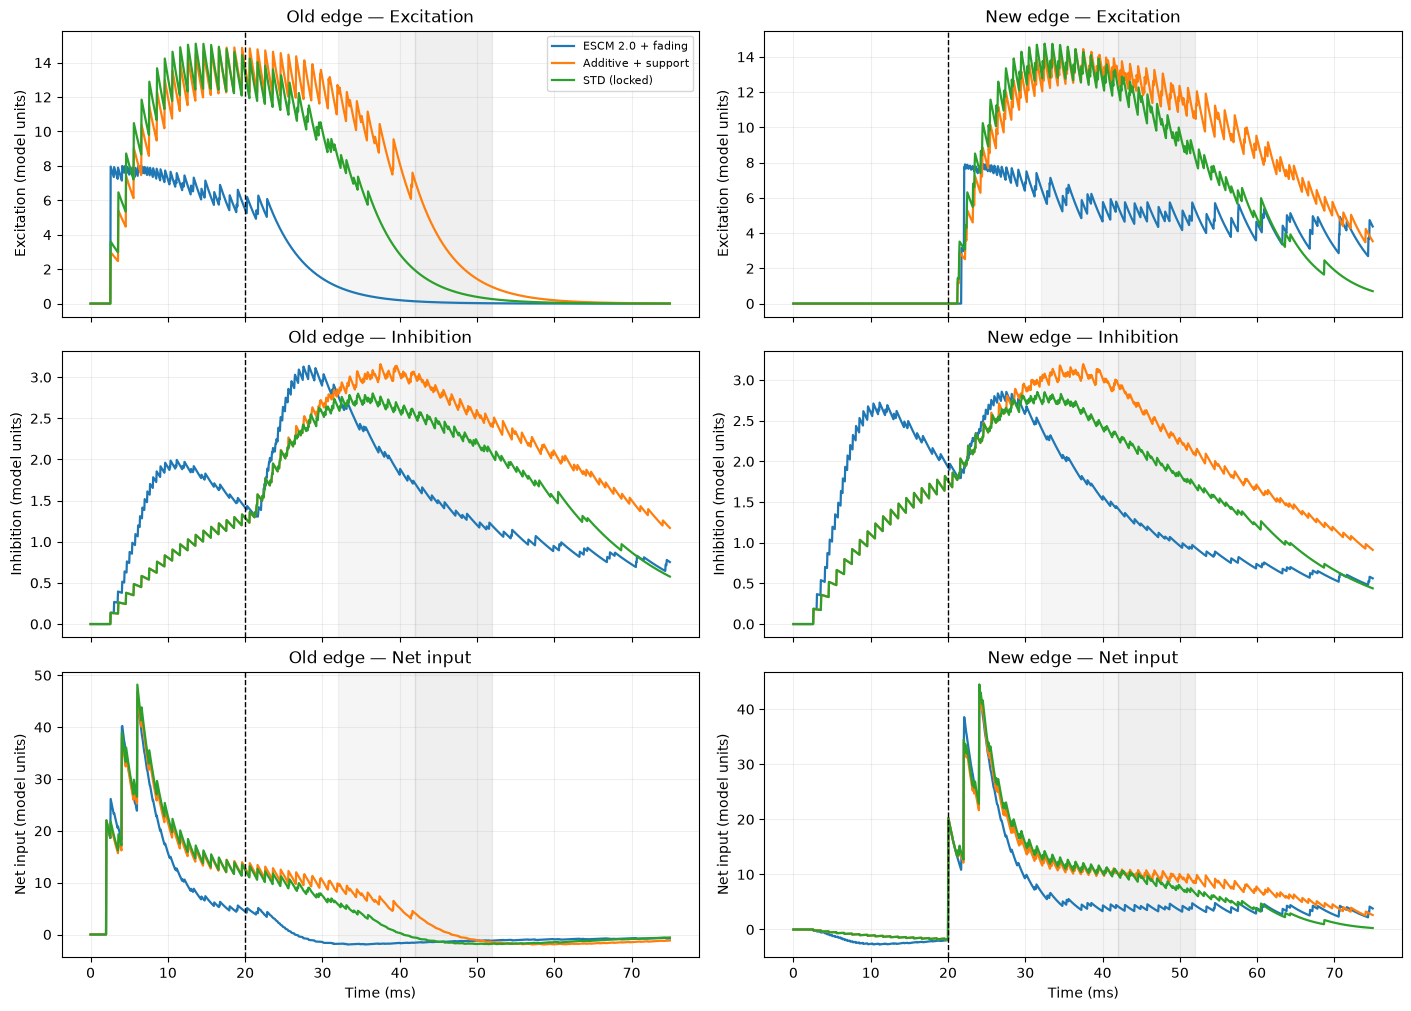

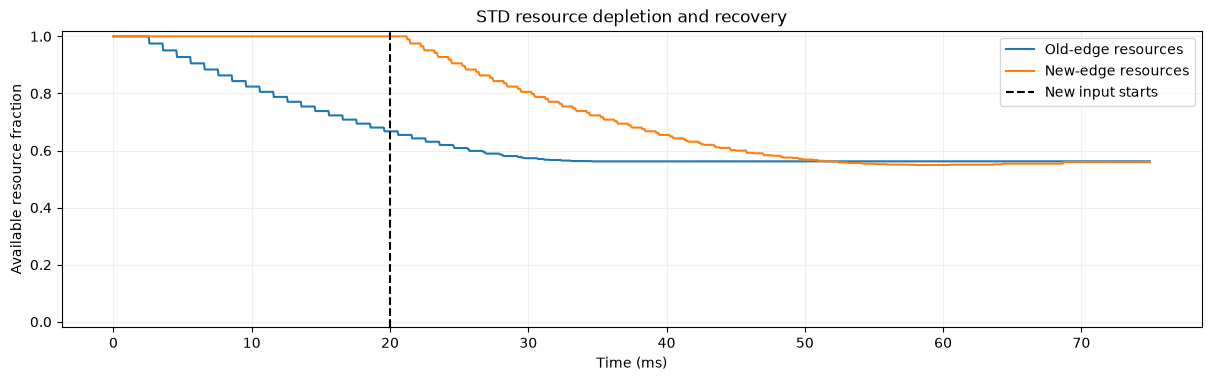

In [8]:
# All models are checked at the same timesteps; do not recalibrate.
resolution_rows = []
for step in tqdm((0.1, 0.05, 0.025), desc="Timestep robustness"):
    for name, cfg in settings.items():
        # simulate() uses a local dt argument; evaluate_one's default is 0.05 ms.
        # Reproduce all held-out geometries explicitly at this resolution.
        for geometry in validation:
            old, new = shapes[geometry]
            old_input, new_input = pulse_schedule(old, new)
            runs = [simulate(s, **cfg, dt=step, duration_ms=80.)
                    for s in ([old_input], [new_input], [old_input, new_input])]
            ow = np.array([pixel_counts(runs[0], old, a, b) for a,b in windows])
            nw = np.array([pixel_counts(runs[1], new, a, b) for a,b in windows])
            bo = np.array([pixel_counts(runs[2], old, a, b) for a,b in windows])
            bn = np.array([pixel_counts(runs[2], new, a, b) for a,b in windows])
            outside = np.setdiff1d(np.arange(n), np.r_[old, new])
            off = any(np.any(pixel_counts(runs[2], outside, a, b)) for a,b in windows)
            eligible = bool((ow >= 2).all() and (nw >= 2).all())
            resolution_rows.append(dict(dt_ms=step, model=name, geometry=geometry,
                                        eligible=eligible, success=bool(eligible and
                                        (bo==0).all() and (bn>=2).all() and not off)))
resolution = pd.DataFrame(resolution_rows)
display(resolution.groupby(["model", "dt_ms"]).agg(
    eligible=("eligible", "sum"), strict_success=("success", "sum")
).reset_index())

old_edge, new_edge = shapes["vertical"]
old_stimulus, new_stimulus = pulse_schedule(old_edge, new_edge)
traces = {}
for name, cfg in tqdm(settings.items(), desc="Current-balance traces"):
    traces[name] = simulate([old_stimulus, new_stimulus], **cfg, duration_ms=75.,
                            trace_ids=list(np.r_[old_edge, new_edge]))

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True, constrained_layout=True)
for name, run in traces.items():
    time = run["time"]
    for col, sl in enumerate((slice(0, 5), slice(5, 10))):
        current_exc = run["Iexc"][sl].mean(axis=0)
        current_inh = run["Iinh"][sl].mean(axis=0)
        net = (run["Iext"] + run["Iexc"] - run["Iinh"])[sl].mean(axis=0)
        for row, value in enumerate((current_exc, current_inh, net)):
            axes[row, col].plot(time, value, label=name, lw=1.6)
for r, unit in enumerate(("Excitation", "Inhibition", "Net input")):
    for c, group in enumerate(("Old edge", "New edge")):
        ax = axes[r, c]
        ax.set(title=f"{group} — {unit}", xlabel="Time (ms)" if r==2 else "",
               ylabel=f"{unit} (model units)")
        ax.axvline(20, color="black", ls="--", lw=1)
        ax.axvspan(32, 42, color="grey", alpha=0.08)
        ax.axvspan(42, 52, color="grey", alpha=0.12)
        ax.grid(alpha=0.2)
axes[0,0].legend(loc="upper right", fontsize=8)
plt.show()

std_trace = traces["STD (locked)"]
fig, ax = plt.subplots(figsize=(12, 3.7), constrained_layout=True)
ax.plot(std_trace["time"], std_trace["x"][:5].mean(axis=0),
        label="Old-edge resources")
ax.plot(std_trace["time"], std_trace["x"][5:].mean(axis=0),
        label="New-edge resources")
ax.axvline(20, color="black", ls="--", label="New input starts")
ax.set(title="STD resource depletion and recovery", xlabel="Time (ms)",
       ylabel="Available resource fraction", ylim=(-0.02, 1.02))
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 9. Interpretation and decision

Use the three independent evidence levels:

1. **Isolated neuron:** Is persistent firing recruited, finite, and bounded by the 1 ms refractory period? Does it cease in a camera-silent tail? Matching exactly 89.2 ms is not required; a useful, robust temporal response is more important.
2. **Held-out geometry:** How many of the six geometries pass strict replacement? Are failures caused by lost isolated controls, poor recruitment, slow suppression, or unwanted activity? Use the per-pixel table, not only the 0/1 score.
3. **Timing and resolution:** Does the configuration remain effective at untrained event timings and at finer integration steps? Report eligible conditions separately. Stability at the tested steps does not establish convergence in general.

A candidate that exceeds ESCM 2.0 on held-out shapes *and* retains sensory fading and reasonable firing behavior is an improvement. If STD reproduces fading but fails replacement, we have still learned that **recovery after depletion differs from a camera-decaying sensory trace**; do not quietly reintroduce sensory support to the STD condition.

**Next decision:** Select whether the locked STD configuration merits full real-recording evaluation. Do not claim real-data superiority from these synthetic tasks; use the full-frame, three-panel timestamp-based visualization only after the synthetic test, without tuning on held-out results.